# Credit Card Fraud Detection

In [ ]:
import os
import zipfile
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

# Load the Dataset

In [22]:
DATA_PATH = r"C:\Users\amans\Downloads\creditcard.csv.zip"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

with zipfile.ZipFile(DATA_PATH, "r") as archive:
    csv_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError("No CSV file found inside ZIP.")

    csv_file = next(
        (
            name for name in csv_files
            if os.path.basename(name).lower()
            == "creditcard.csv"
        ),
        csv_files[0]
    )

    with archive.open(csv_file) as file:
        df = pd.read_csv(file)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [23]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 284807
Number of columns: 31


In [24]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [25]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

In [26]:
print("\nStatistical summary:")
display(df.describe().T)


Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


# Missing Value

In [27]:
# Normalize column names
df.columns = df.columns.str.strip()

# Validate the target column
if "Class" not in df.columns:
    raise ValueError(
        "The target column 'Class' is missing. "
        "Check whether the correct dataset was loaded."
    )

# Convert target to numeric and remove invalid labels
df["Class"] = pd.to_numeric(df["Class"], errors="coerce")
df = df.dropna(subset=["Class"]).copy()

# Keep only binary target labels
df = df[df["Class"].isin([0, 1])].copy()
df["Class"] = df["Class"].astype(int)

# Convert features to numeric
feature_columns = [col for col in df.columns if col != "Class"]

for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check missing values
print("Missing values before feature cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

# Remove rows with missing feature values
df = df.dropna(subset=feature_columns).copy()

# Remove exact duplicate rows
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

print("\nExact duplicate rows removed:", duplicates_before)
print("Cleaned dataset dimensions:", df.shape)
print("Missing values remaining:", int(df.isnull().sum().sum()))

print("\nClass distribution after cleaning:")
display(df["Class"].value_counts().to_frame("Transaction Count"))

if df["Class"].nunique() != 2:
    raise ValueError("The dataset must contain both classes: 0 and 1.")

Missing values before feature cleaning:


,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0



Exact duplicate rows removed: 1081
Cleaned dataset dimensions: (283726, 31)
Missing values remaining: 0

Class distribution after cleaning:


,Transaction Count
Class,
0,283253
1,473


# Distribution of Legitimate and Fraudulent Transactions

Legitimate transactions: 283253
Fraudulent transactions: 473
Total transactions: 283726
Fraud percentage: 0.1667%


,Transaction Type,Count
0,Legitimate,283253
1,Fraud,473


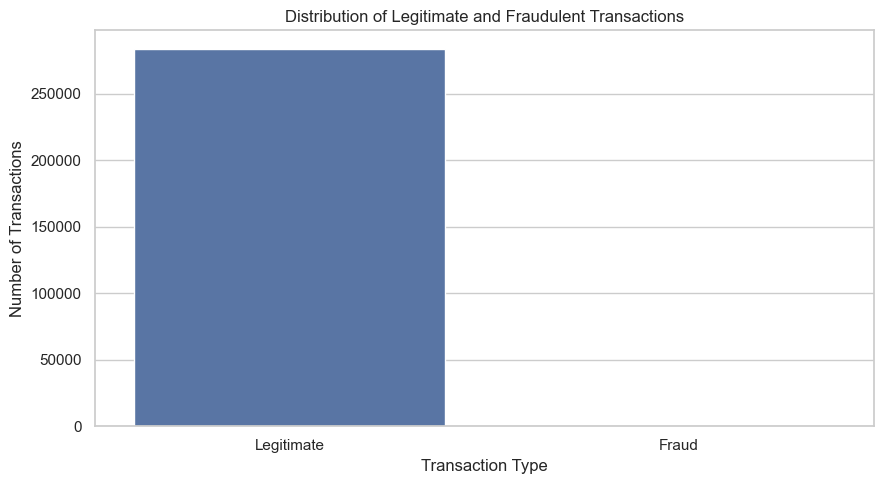

In [28]:
class_counts = df["Class"].value_counts().sort_index()

legitimate_count = int(class_counts.get(0, 0))
fraud_count = int(class_counts.get(1, 0))

print("Legitimate transactions:", legitimate_count)
print("Fraudulent transactions:", fraud_count)
print("Total transactions:", len(df))

fraud_percentage = (fraud_count / len(df)) * 100

print(f"Fraud percentage: {fraud_percentage:.4f}%")

class_summary = pd.DataFrame({
    "Transaction Type": ["Legitimate", "Fraud"],
    "Count": [legitimate_count, fraud_count]
})

display(class_summary)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=class_summary,
    x="Transaction Type",
    y="Count"
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# Percentage Distribution of Transaction Classes

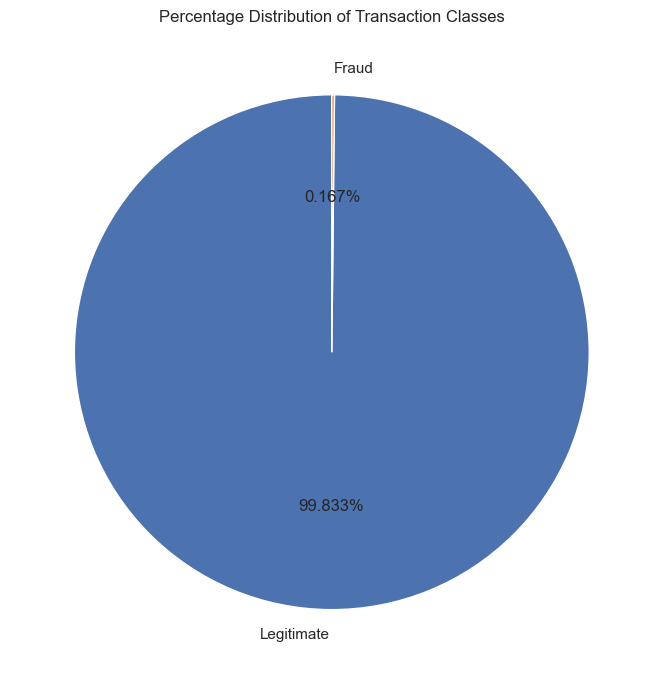

Class percentages:


,Percentage
Class,
0,99.83329
1,0.16671


In [29]:
class_percentage = (
    df["Class"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

plt.figure(figsize=(7, 7))

plt.pie(
    class_percentage.values,
    labels=["Legitimate", "Fraud"],
    autopct="%1.3f%%",
    startangle=90
)

plt.title("Percentage Distribution of Transaction Classes")
plt.tight_layout()
plt.show()

print("Class percentages:")
display(
    class_percentage.rename("Percentage").to_frame()
)

# Analyze transaction amounts

Transaction amount statistics:


,Amount
count,283726.000000
mean,88.472687
std,250.399437
min,0.000000
25%,5.600000
50%,22.000000
75%,77.510000
max,25691.160000


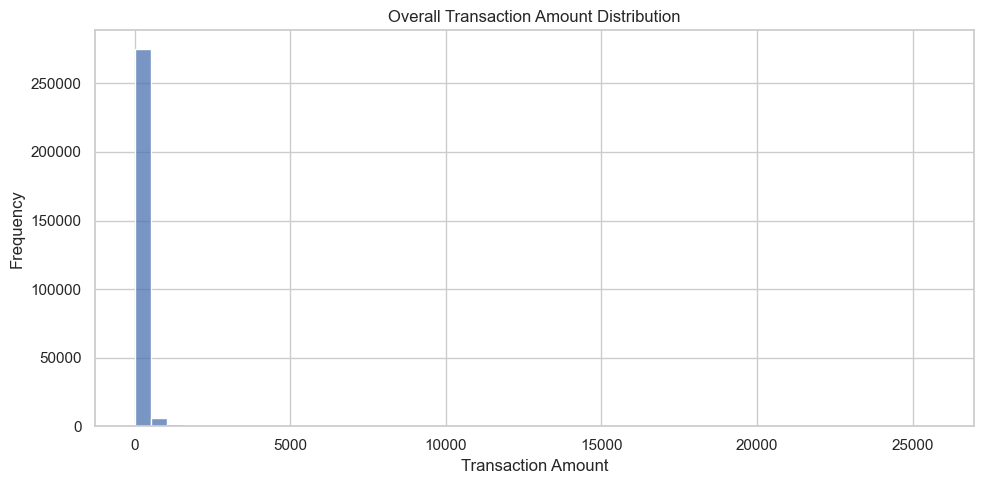

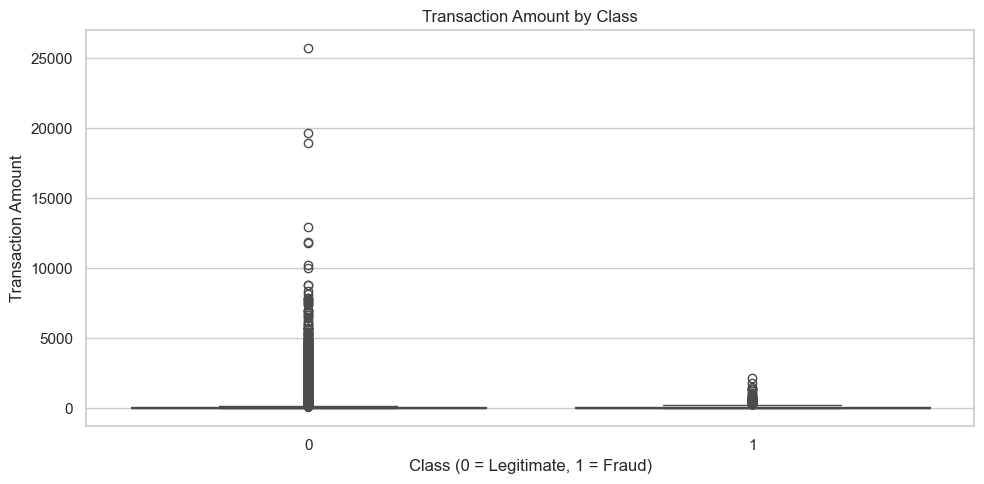

,count,mean,median,min,max
Class,,,,,
0,283253,88.413575,22.00,0.0,25691.16
1,473,123.871860,9.82,0.0,2125.87


In [30]:
if "Amount" in df.columns:

    print("Transaction amount statistics:")
    display(df["Amount"].describe().to_frame())

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x="Amount",
        bins=50
    )

    plt.title("Overall Transaction Amount Distribution")
    plt.xlabel("Transaction Amount")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x="Class",
        y="Amount"
    )

    plt.title("Transaction Amount by Class")
    plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
    plt.ylabel("Transaction Amount")
    plt.tight_layout()
    plt.show()

    # Compare average amounts
    amount_summary = df.groupby("Class")["Amount"].agg(
        ["count", "mean", "median", "min", "max"]
    )

    display(amount_summary)

# Analyze transaction time

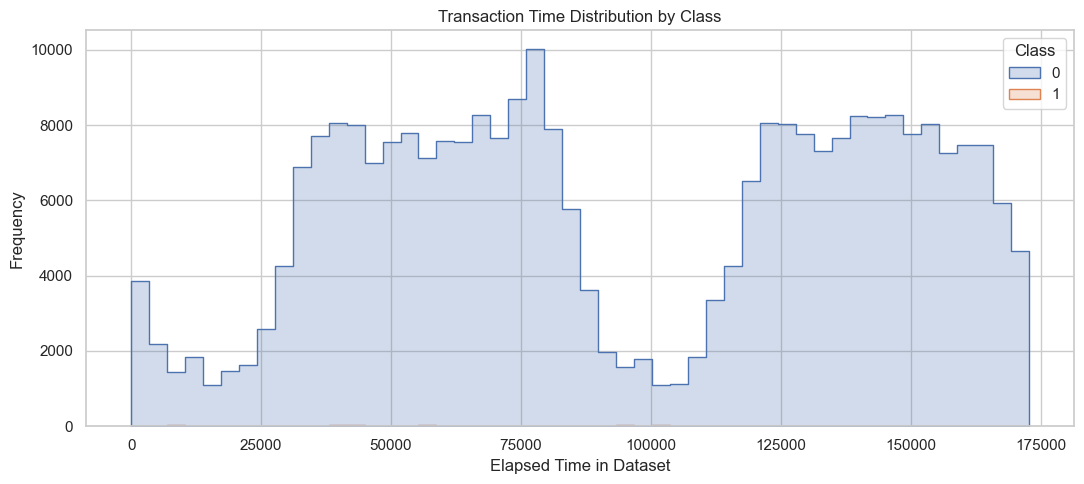

Time statistics by transaction class:


,mean,median,min,max
Class,,,,
0,94835.058093,84711.0,0.0,172792.0
1,80450.513742,73408.0,406.0,170348.0


In [32]:
if "Time" in df.columns:

    plt.figure(figsize=(11, 5))

    sns.histplot(
        data=df,
        x="Time",
        hue="Class",
        bins=50,
        element="step",
        common_norm=False
    )

    plt.title("Transaction Time Distribution by Class")
    plt.xlabel("Elapsed Time in Dataset")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    time_summary = df.groupby("Class")["Time"].agg(
        ["mean", "median", "min", "max"]
    )

    print("Time statistics by transaction class:")
    display(time_summary)

# Correlation analysis

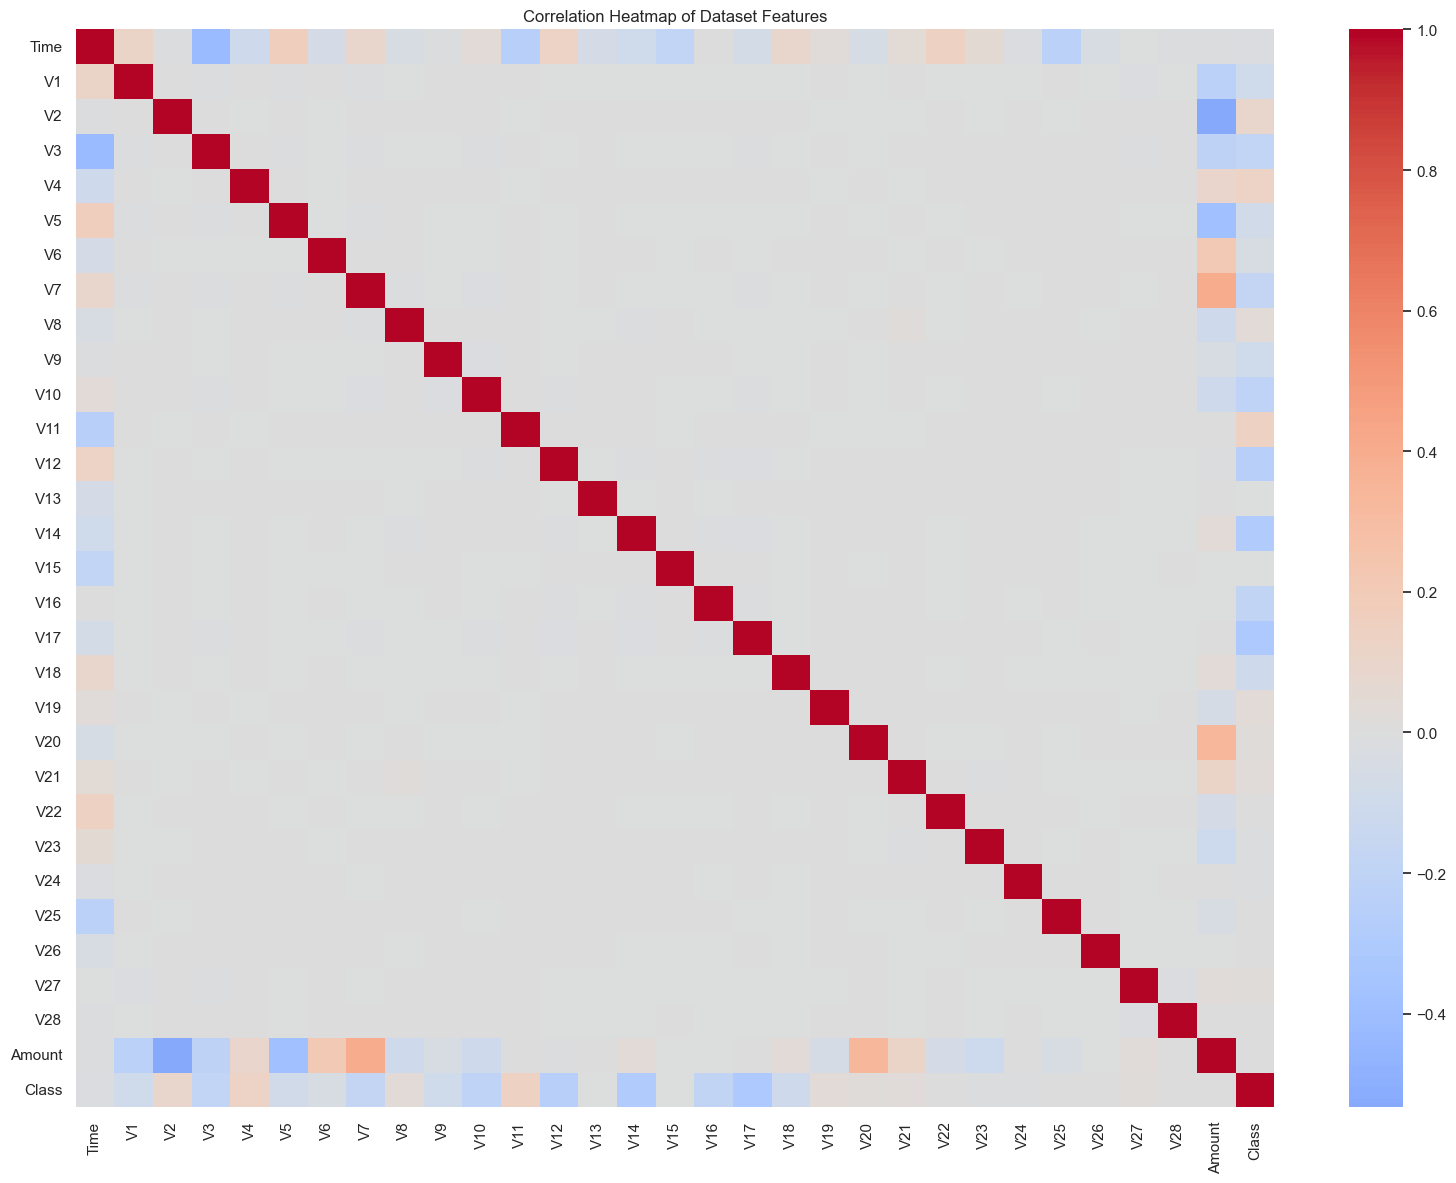

Features with strongest absolute correlation to Class:


,Correlation
V17,-0.313498
V14,-0.293375
V12,-0.250711
V10,-0.206971
V16,-0.187186
V3,-0.182322
V7,-0.172347
V11,0.149067
V4,0.129326
V18,-0.105340


In [33]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    square=False
)

plt.title("Correlation Heatmap of Dataset Features")
plt.tight_layout()
plt.show()

# Correlation of features with target
target_correlation = (
    correlation_matrix["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

print("Features with strongest absolute correlation to Class:")
display(target_correlation.head(15).to_frame("Correlation"))

# Prepare the features and target

In [34]:
# X contains input features
# y contains the target class

X = df.drop(columns=["Class"]).copy()
y = df["Class"].copy()

# Ensure every model input is numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Remove any columns that are entirely missing
X = X.dropna(axis=1, how="all")

# Remove any remaining rows with missing input values
valid_rows = X.notna().all(axis=1)

X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

print("\nTarget distribution:")
display(y.value_counts().to_frame("Count"))

Feature matrix shape: (283726, 30)
Target vector shape: (283726,)

Features used:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Target distribution:


,Count
Class,
0,283253
1,473


# Split the data into training and testing sets

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
display(y_train.value_counts().to_frame("Count"))

print("\nTesting target distribution:")
display(y_test.value_counts().to_frame("Count"))

print(
    "\nTraining fraud rate:",
    f"{y_train.mean() * 100:.4f}%"
)

print(
    "Testing fraud rate:",
    f"{y_test.mean() * 100:.4f}%"
)

Training samples: 226980
Testing samples: 56746

Training target distribution:


,Count
Class,
0,226602
1,378



Testing target distribution:


,Count
Class,
0,56651
1,95



Training fraud rate: 0.1665%
Testing fraud rate: 0.1674%


# Calculate class imbalance weight for XGBoost

In [36]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

if positive_count == 0:
    raise ValueError("No fraudulent transactions in the training set.")

scale_pos_weight = negative_count / positive_count

print("Legitimate training transactions:", negative_count)
print("Fraudulent training transactions:", positive_count)

print(
    "XGBoost scale_pos_weight:",
    round(scale_pos_weight, 3)
)

Legitimate training transactions: 226602
Fraudulent training transactions: 378
XGBoost scale_pos_weight: 599.476


# Create the Logistic Regression model

In [37]:
logistic_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

print("Logistic Regression model created.")

Logistic Regression model created.


# Create the Random Forest model

In [38]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Random Forest model created.")

Random Forest model created.


# Create the XGBoost model

In [39]:
xgboost_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="auc",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("XGBoost model created.")

XGBoost model created.


# Train all three models

In [ ]:
models = {
    "Logistic Regression": logistic_regression,
    "Random Forest": random_forest,
    "XGBoost": xgboost_model
}

trained_models = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    model.fit(X_train, y_train)

    trained_models[model_name] = model

    print(model_name, "training completed successfully.")

print("\nAll models trained successfully!")


Training: Logistic Regression
Logistic Regression training completed successfully.

Training: Random Forest


# Compare Accuracy, Precision, Recall and F1-score

In [49]:
# Select the highest ROC-AUC model from the comparison.
# This is a preliminary selection; ideally tune on validation data.

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_result = results_df.iloc[0]

print("=" * 60)
print("BEST MODEL")
print("=" * 60)

print("Model:", best_model_name)
print(f"Accuracy : {best_result['Accuracy']:.4f}")
print(f"Precision: {best_result['Precision']:.4f}")
print(f"Recall   : {best_result['Recall']:.4f}")
print(f"F1-Score : {best_result['F1_Score']:.4f}")
print(f"ROC-AUC  : {best_result['ROC_AUC']:.4f}")
print(f"PR-AUC   : {best_result['PR_AUC']:.4f}")

if best_result["ROC_AUC"] >= 0.94:
    print("\nROC-AUC target of 0.94 reached.")
else:
    print("\nROC-AUC target of 0.94 not reached.")

BEST MODEL
Model: XGBoost
Accuracy : 0.9995
Precision: 0.8636
Recall   : 0.8000
F1-Score : 0.8306
ROC-AUC  : 0.9759
PR-AUC   : 0.8167

ROC-AUC target of 0.94 reached.


# Compare ROC-AUC scores

,Threshold,Accuracy,Precision,Recall,F1_Score
0,0.10,0.9982,0.4785,0.8211,0.6047
1,0.20,0.9990,0.6581,0.8105,0.7264
2,0.30,0.9993,0.7700,0.8105,0.7897
3,0.40,0.9994,0.8191,0.8105,0.8148
4,0.50,0.9995,0.8636,0.8000,0.8306
5,0.60,0.9995,0.9048,0.8000,0.8492


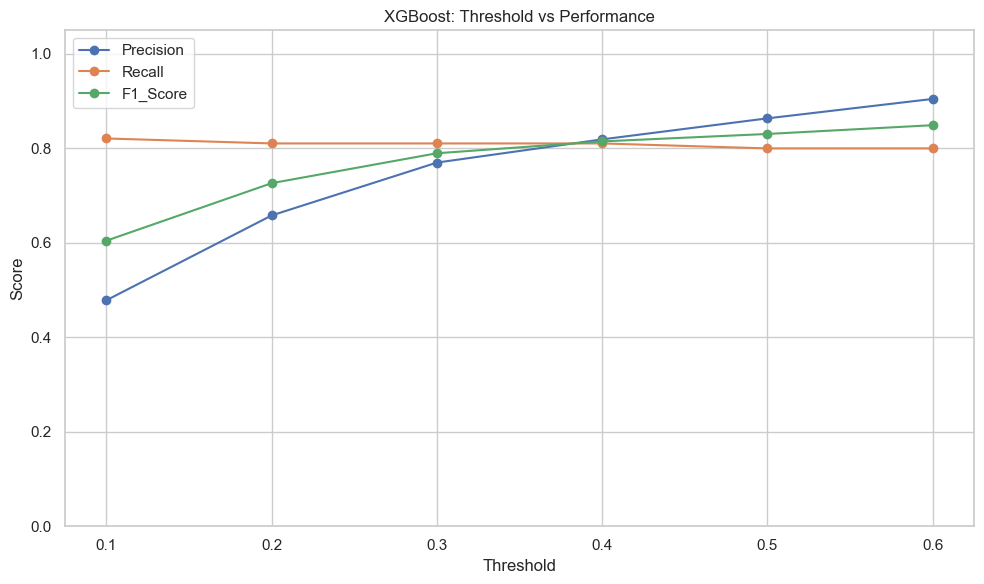

In [50]:
# Illustrative threshold comparison for XGBoost.
# For final model selection, tune the threshold on validation data.

threshold_model_name = "XGBoost"

xgb_probabilities = probabilities[threshold_model_name]

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]:

    threshold_predictions = (
        xgb_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test, threshold_predictions
        ),
        "Precision": precision_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, threshold_predictions, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}"
    })
)

threshold_results_df.set_index("Threshold")[
    ["Precision", "Recall", "F1_Score"]
].plot(
    marker="o",
    figsize=(10, 6)
)

plt.title("XGBoost: Threshold vs Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

# Compare Accuracy, Precision, Recall and F1-score

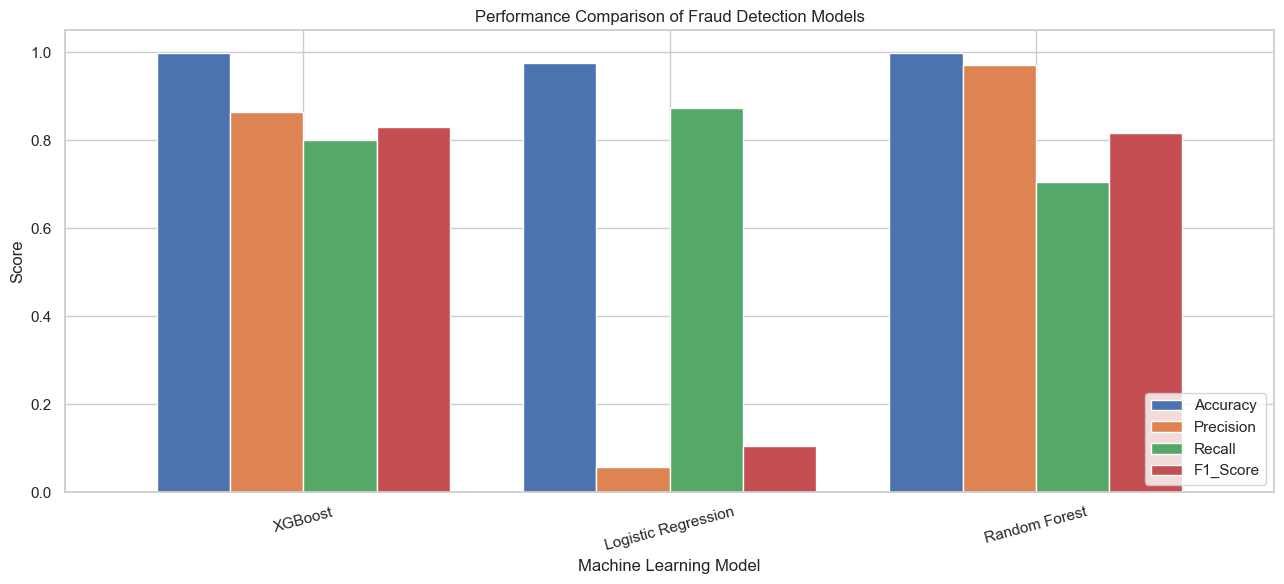

In [66]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score"
]

plot_df = results_df.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1.05),
    width=0.8
)

ax.set_title("Performance Comparison of Fraud Detection Models")
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# Compare ROC-AUC scores

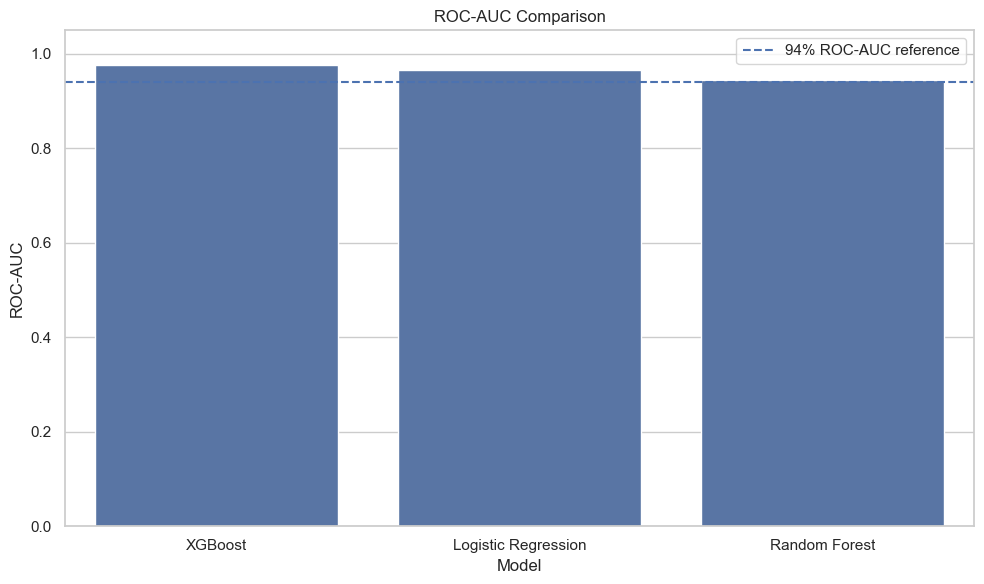

Actual ROC-AUC results:


,Model,ROC_AUC
0,XGBoost,0.975856
1,Logistic Regression,0.965655
2,Random Forest,0.944373


In [67]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC_AUC"
)

plt.axhline(
    y=0.94,
    linestyle="--",
    label="94% ROC-AUC reference"
)

plt.title("ROC-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

print("Actual ROC-AUC results:")
display(results_df[["Model", "ROC_AUC"]])

# Plot confusion matrices for all models

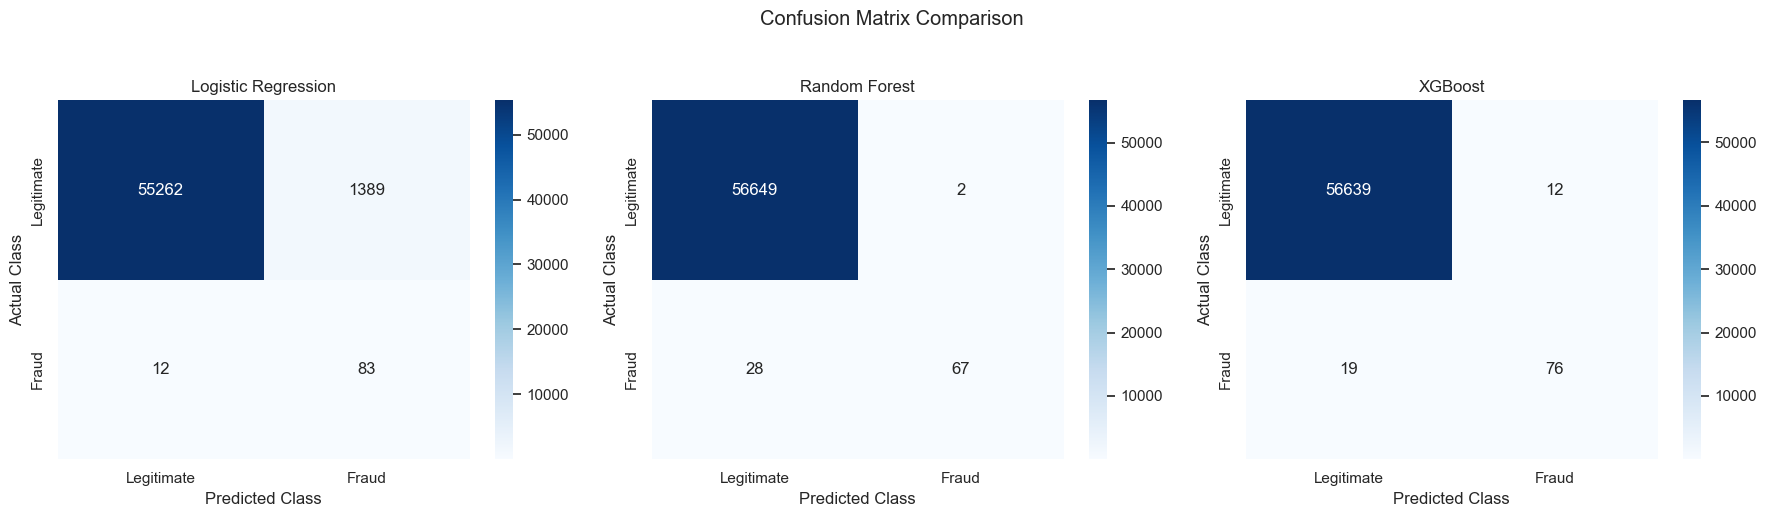

In [68]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, model_name in zip(axes, trained_models):

    cm = confusion_matrices[model_name]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle("Confusion Matrix Comparison", y=1.03)
plt.tight_layout()
plt.show()

# Plot ROC curves

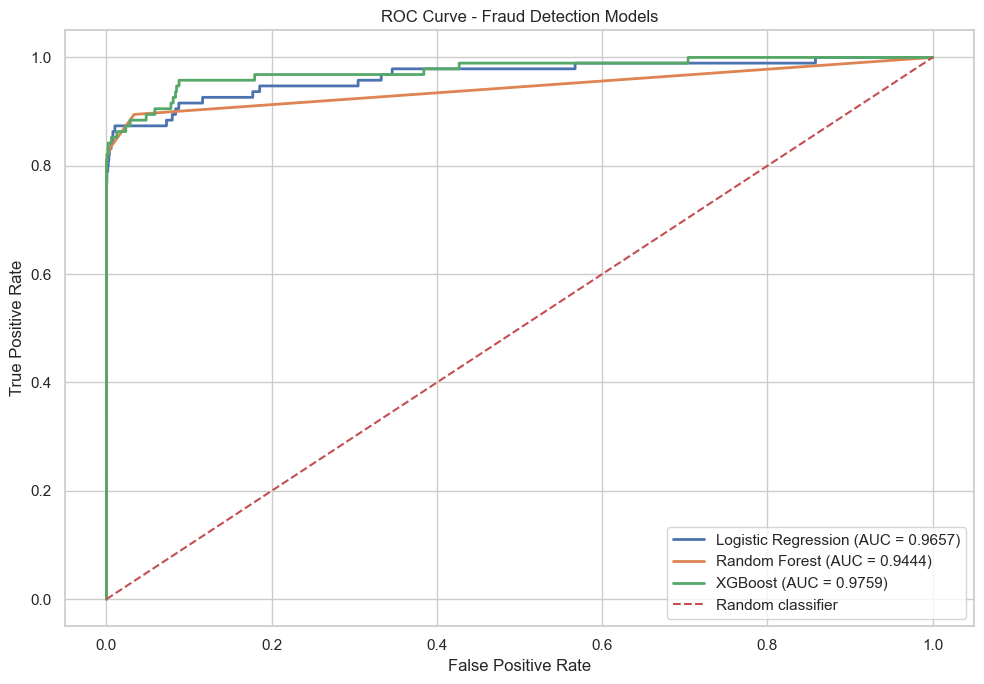

,Model,False_Positive_Rate,True_Positive_Rate,Threshold
0,Logistic Regression,0.000000,0.000000,inf
1,Logistic Regression,0.000141,0.326316,1.0
2,Logistic Regression,0.000159,0.357895,1.0
3,Logistic Regression,0.000159,0.389474,1.0
4,Logistic Regression,0.000159,0.400000,1.0


In [69]:
roc_curve_data = []

plt.figure(figsize=(10, 7))

for model_name in trained_models:

    y_prob = probabilities[model_name]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_value = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

    temp_df = pd.DataFrame({
        "Model": model_name,
        "False_Positive_Rate": fpr,
        "True_Positive_Rate": tpr,
        "Threshold": thresholds
    })

    roc_curve_data.append(temp_df)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fraud Detection Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

roc_curve_df = pd.concat(
    roc_curve_data,
    ignore_index=True
)

display(roc_curve_df.head())

# Plot ROC curves

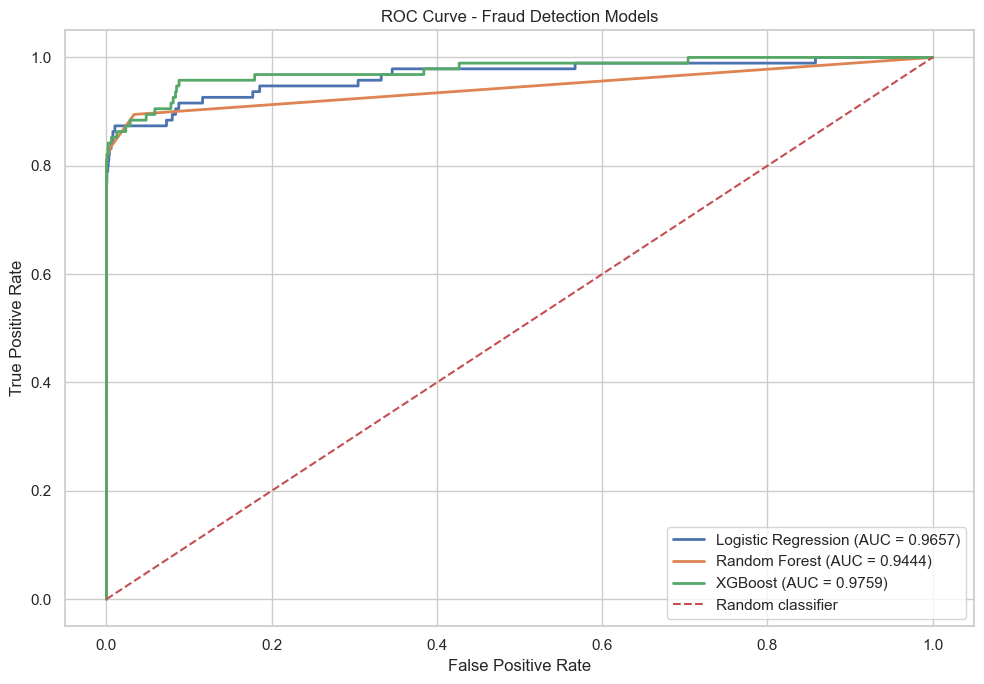

,Model,False_Positive_Rate,True_Positive_Rate,Threshold
0,Logistic Regression,0.000000,0.000000,inf
1,Logistic Regression,0.000141,0.326316,1.0
2,Logistic Regression,0.000159,0.357895,1.0
3,Logistic Regression,0.000159,0.389474,1.0
4,Logistic Regression,0.000159,0.400000,1.0


In [70]:
roc_curve_data = []

plt.figure(figsize=(10, 7))

for model_name in trained_models:

    y_prob = probabilities[model_name]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_value = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

    temp_df = pd.DataFrame({
        "Model": model_name,
        "False_Positive_Rate": fpr,
        "True_Positive_Rate": tpr,
        "Threshold": thresholds
    })

    roc_curve_data.append(temp_df)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fraud Detection Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

roc_curve_df = pd.concat(
    roc_curve_data,
    ignore_index=True
)

display(roc_curve_df.head())

# Calculate false positives and false negatives

In [81]:

import numpy as np
import pandas as pd

# ================================================================
# BUILD TRANSACTION-LEVEL REPORT
# ================================================================

transaction_report = X_test.copy().reset_index(drop=True)

# Add actual class labels
transaction_report["Actual_Class"] = (
    np.asarray(y_test).ravel()
)

# Add actual transaction status
transaction_report["Actual_Status"] = np.where(
    transaction_report["Actual_Class"] == 1,
    "Fraud",
    "Legitimate"
)

# Add predictions and fraud probabilities for each model
for model_name in trained_models:

    # Create consistent column prefix
    safe_name = (
        model_name.strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    # Add predicted class
    transaction_report[f"{safe_name}_prediction"] = (
        np.asarray(predictions[model_name]).ravel()
    )

    # Add fraud probability if available
    if model_name in probabilities:
        transaction_report[
            f"{safe_name}_fraud_probability"
        ] = np.asarray(probabilities[model_name]).ravel()

# ================================================================
# ADD XGBOOST PREDICTED STATUS
# ================================================================

# Find the XGBoost prediction column automatically
xgb_prediction_columns = [
    col for col in transaction_report.columns
    if col.lower() == "xgboost_prediction"
]

if xgb_prediction_columns:
    xgb_col = xgb_prediction_columns[0]

    transaction_report["XGBoost_Predicted_Status"] = np.where(
        transaction_report[xgb_col] == 1,
        "Fraud",
        "Legitimate"
    )

else:
    print(
        "Warning: XGBoost prediction column not found. "
        "Available columns:",
        transaction_report.columns.tolist()
    )

# ================================================================
# DISPLAY REPORT
# ================================================================

print("Transaction-Level Fraud Detection Report")
print("-" * 60)

display(transaction_report.head(10))

print("\nReport shape:", transaction_report.shape)
print("\nAvailable columns:")
print(transaction_report.columns.tolist())


Transaction-Level Fraud Detection Report
------------------------------------------------------------


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,Amount,Actual_Class,Actual_Status,logistic_regression_prediction,logistic_regression_fraud_probability,random_forest_prediction,random_forest_fraud_probability,xgboost_prediction,xgboost_fraud_probability,XGBoost_Predicted_Status
0,61290.0,1.228821,-0.063408,0.274145,0.647465,-0.048135,0.372073,-0.224231,0.079939,0.640759,...,11.50,0,Legitimate,0,0.021626,0,0.0,0,0.000027,Legitimate
1,155394.0,-0.203154,1.176678,-0.759595,-0.518472,0.629649,-0.721675,0.638893,0.243377,-0.157488,...,1.94,0,Legitimate,0,0.020072,0,0.0,0,0.000071,Legitimate
2,30881.0,-1.672836,1.401297,1.503940,2.175491,0.699791,1.062139,1.114364,-0.535822,-0.252983,...,91.28,0,Legitimate,0,0.010240,0,0.0,0,0.001019,Legitimate
3,53203.0,0.819379,-1.124913,0.515025,0.513945,-1.009048,0.488484,-0.580672,0.187686,-0.999142,...,228.00,0,Legitimate,0,0.015720,0,0.0,0,0.000083,Legitimate
4,129429.0,2.009701,0.105635,-1.752759,0.588312,0.374801,-0.637884,0.009260,-0.129487,0.492619,...,1.41,0,Legitimate,0,0.219235,0,0.0,0,0.001217,Legitimate
5,64816.0,1.100851,0.157223,0.460898,1.144401,-0.262777,-0.207127,-0.069886,0.108077,-0.189285,...,20.99,0,Legitimate,0,0.060807,0,0.0,0,0.000210,Legitimate
6,27650.0,-1.428601,-0.230183,0.913877,-0.555968,0.934244,-0.490981,1.585359,-0.453572,-0.813235,...,234.90,0,Legitimate,0,0.022125,0,0.0,0,0.000091,Legitimate
7,27485.0,-0.915128,0.500570,0.169310,-0.839501,3.080748,3.550344,0.456991,0.626990,-0.094290,...,21.44,0,Legitimate,0,0.038480,0,0.0,0,0.000005,Legitimate
8,111433.0,1.905170,-0.048129,-0.606486,1.669746,0.140037,0.201096,-0.171609,-0.052682,2.057745,...,20.00,0,Legitimate,0,0.086821,0,0.0,0,0.000976,Legitimate
9,138819.0,-1.461922,0.398294,0.518684,-1.064658,0.552358,2.088577,-0.345377,1.142239,0.294364,...,59.82,0,Legitimate,0,0.001801,0,0.0,0,0.000015,Legitimate



Report shape: (56746, 39)

Available columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Actual_Class', 'Actual_Status', 'logistic_regression_prediction', 'logistic_regression_fraud_probability', 'random_forest_prediction', 'random_forest_fraud_probability', 'xgboost_prediction', 'xgboost_fraud_probability', 'XGBoost_Predicted_Status']


In [82]:

import os

# Define project output folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

# Create folder if it does not exist
os.makedirs(PROJECT_FOLDER, exist_ok=True)

# Export model comparison results
metrics_path = os.path.join(
    PROJECT_FOLDER,
    "model_comparison.csv"
)

results_df.to_csv(
    metrics_path,
    index=False
)

print("Model comparison exported successfully!")
print("File location:", metrics_path)


Model comparison exported successfully!
File location: C:\Users\amans\fraud_detection_output\model_comparison.csv


In [83]:

import os
import pandas as pd

# 1. Define and create the project folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

os.makedirs(PROJECT_FOLDER, exist_ok=True)

# 2. Prepare confusion matrix data
confusion_rows = []

class_labels = ["Legitimate", "Fraud"]

for model_name, cm in confusion_matrices.items():

    for actual_idx, actual_label in enumerate(class_labels):

        for predicted_idx, predicted_label in enumerate(class_labels):

            confusion_rows.append({
                "Model": model_name,
                "Actual": actual_label,
                "Predicted": predicted_label,
                "Count": int(cm[actual_idx, predicted_idx])
            })

# 3. Create DataFrame
confusion_export_df = pd.DataFrame(confusion_rows)

# 4. Export confusion matrix CSV
confusion_path = os.path.join(
    PROJECT_FOLDER,
    "confusion_matrix.csv"
)

confusion_export_df.to_csv(
    confusion_path,
    index=False
)

# 5. Display results
print("Confusion Matrix Exported Successfully!")
display(confusion_export_df.head(12))

print("\nFile location:")
print(confusion_path)


Confusion Matrix Exported Successfully!


,Model,Actual,Predicted,Count
0,Logistic Regression,Legitimate,Legitimate,55262
1,Logistic Regression,Legitimate,Fraud,1389
2,Logistic Regression,Fraud,Legitimate,12
3,Logistic Regression,Fraud,Fraud,83
4,Random Forest,Legitimate,Legitimate,56649
5,Random Forest,Legitimate,Fraud,2
6,Random Forest,Fraud,Legitimate,28
7,Random Forest,Fraud,Fraud,67
8,XGBoost,Legitimate,Legitimate,56639
9,XGBoost,Legitimate,Fraud,12



File location:
C:\Users\amans\fraud_detection_output\confusion_matrix.csv


In [84]:

import os
import pandas as pd

# 1. Define and create the output folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

os.makedirs(PROJECT_FOLDER, exist_ok=True)

# 2. Check whether ROC curve data exists
if "roc_curve_df" in globals() and not roc_curve_df.empty:

    # 3. Export ROC curve data
    roc_path = os.path.join(
        PROJECT_FOLDER,
        "roc_curve_data.csv"
    )

    roc_curve_df.to_csv(
        roc_path,
        index=False
    )

    print("ROC curve data exported successfully!")
    print("File location:", roc_path)

    display(roc_curve_df.head())

else:
    print(
        "ROC curve data is missing or empty. "
        "Run the cell that generates roc_curve_df first."
    )


ROC curve data exported successfully!
File location: C:\Users\amans\fraud_detection_output\roc_curve_data.csv


,Model,False_Positive_Rate,True_Positive_Rate,Threshold
0,Logistic Regression,0.000000,0.000000,inf
1,Logistic Regression,0.000141,0.326316,1.0
2,Logistic Regression,0.000159,0.357895,1.0
3,Logistic Regression,0.000159,0.389474,1.0
4,Logistic Regression,0.000159,0.400000,1.0


In [85]:

import os
import pandas as pd

# 1. Define project output folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

# 2. Create folder if it does not exist
os.makedirs(PROJECT_FOLDER, exist_ok=True)

# 3. Check and export feature importance data
if "feature_importance_df" in globals() and not feature_importance_df.empty:

    importance_path = os.path.join(
        PROJECT_FOLDER,
        "feature_importance.csv"
    )

    feature_importance_df.to_csv(
        importance_path,
        index=False
    )

    print("Feature importance exported successfully!")
    print("File location:", importance_path)

    display(feature_importance_df.head())

else:
    print(
        "feature_importance_df is missing or empty. "
        "Run the cell that generates feature importance first."
    )


feature_importance_df is missing or empty. Run the cell that generates feature importance first.


In [86]:

import os
import pandas as pd

# 1. Define the project output folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

# 2. Create the folder if it does not exist
os.makedirs(PROJECT_FOLDER, exist_ok=True)

# 3. Check and export fraud error analysis
if "error_analysis_df" in globals() and not error_analysis_df.empty:

    error_analysis_path = os.path.join(
        PROJECT_FOLDER,
        "fraud_error_analysis.csv"
    )

    error_analysis_df.to_csv(
        error_analysis_path,
        index=False
    )

    print("Fraud error analysis exported successfully!")
    print("File location:", error_analysis_path)

    display(error_analysis_df.head(10))

else:
    print(
        "error_analysis_df is missing or empty. "
        "Run the cell that generates error_analysis_df first."
    )


Fraud error analysis exported successfully!
File location: C:\Users\amans\fraud_detection_output\fraud_error_analysis.csv


,Model,True_Negatives,False_Positives,False_Negatives,True_Positives,Fraud_Detection_Rate,False_Alarm_Rate
0,Logistic Regression,55262,1389,12,83,0.873684,0.024519
1,Random Forest,56649,2,28,67,0.705263,0.000035
2,XGBoost,56639,12,19,76,0.800000,0.000212


In [87]:

import os
import pandas as pd

# 1. Define and create the project output folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

os.makedirs(PROJECT_FOLDER, exist_ok=True)

# 2. Generate dataset summary
dataset_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Legitimate Transactions",
        "Fraudulent Transactions",
        "Fraud Percentage",
        "Number of Features",
        "Training Transactions",
        "Testing Transactions"
    ],
    "Value": [
        len(df),
        int((df["Class"] == 0).sum()),
        int((df["Class"] == 1).sum()),
        round(float((df["Class"] == 1).mean() * 100), 4),
        X.shape[1],
        len(X_train),
        len(X_test)
    ]
})

# 3. Export dataset summary
summary_path = os.path.join(
    PROJECT_FOLDER,
    "dataset_summary.csv"
)

dataset_summary.to_csv(
    summary_path,
    index=False
)

# 4. Display results
print("Dataset summary exported successfully!")
display(dataset_summary)

print("\nFile location:")
print(summary_path)


Dataset summary exported successfully!


,Metric,Value
0,Total Transactions,283726.0000
1,Legitimate Transactions,283253.0000
2,Fraudulent Transactions,473.0000
3,Fraud Percentage,0.1667
4,Number of Features,30.0000
5,Training Transactions,226980.0000
6,Testing Transactions,56746.0000



File location:
C:\Users\amans\fraud_detection_output\dataset_summary.csv


In [88]:

import os
import joblib

# 1. Define and create the project output folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

os.makedirs(PROJECT_FOLDER, exist_ok=True)

# 2. Save every trained model
for model_name, model in trained_models.items():

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    model_path = os.path.join(
        PROJECT_FOLDER,
        f"{safe_name}_model.joblib"
    )

    joblib.dump(model, model_path)

    print(f"{model_name} saved to:")
    print(model_path)

# 3. Save the selected best model
best_model_path = os.path.join(
    PROJECT_FOLDER,
    "best_fraud_detection_model.joblib"
)

joblib.dump(best_model, best_model_path)

# 4. Save feature names in training order
feature_columns_path = os.path.join(
    PROJECT_FOLDER,
    "feature_columns.joblib"
)

joblib.dump(
    list(X_train.columns),
    feature_columns_path
)

# 5. Confirm saved files
print("\nAll models and feature columns saved successfully!")
print("Best model:", best_model_path)
print("Feature columns:", feature_columns_path)
print("Output folder:", PROJECT_FOLDER)


Logistic Regression saved to:
C:\Users\amans\fraud_detection_output\logistic_regression_model.joblib
Random Forest saved to:
C:\Users\amans\fraud_detection_output\random_forest_model.joblib
XGBoost saved to:
C:\Users\amans\fraud_detection_output\xgboost_model.joblib

All models and feature columns saved successfully!
Best model: C:\Users\amans\fraud_detection_output\best_fraud_detection_model.joblib
Feature columns: C:\Users\amans\fraud_detection_output\feature_columns.joblib
Output folder: C:\Users\amans\fraud_detection_output


In [89]:

import os
import joblib
import numpy as np

from sklearn.metrics import accuracy_score, roc_auc_score

# 1. Define the project folder
PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

# 2. Define the saved best-model path
best_model_path = os.path.join(
    PROJECT_FOLDER,
    "best_fraud_detection_model.joblib"
)

# 3. Check that the model file exists
if not os.path.isfile(best_model_path):
    raise FileNotFoundError(
        f"Saved model not found: {best_model_path}\n"
        "Run the model-saving cell first."
    )

# 4. Load the saved model
loaded_model = joblib.load(best_model_path)

# 5. Generate predictions
loaded_predictions = loaded_model.predict(X_test)

# 6. Calculate fraud probabilities
if not hasattr(loaded_model, "predict_proba"):
    raise AttributeError(
        "The saved model does not support predict_proba()."
    )

probability_matrix = loaded_model.predict_proba(X_test)

# Find the probability column corresponding to fraud class 1
model_classes = np.asarray(loaded_model.classes_)
fraud_indices = np.where(model_classes == 1)[0]

if len(fraud_indices) == 0:
    raise ValueError("Fraud class 1 was not found in model classes.")

loaded_probabilities = probability_matrix[:, fraud_indices[0]]

# 7. Evaluate the loaded model
print("Saved model loaded successfully!")

print(
    "Loaded model accuracy:",
    round(accuracy_score(y_test, loaded_predictions), 4)
)

if len(np.unique(y_test)) == 2:
    print(
        "Loaded model ROC-AUC:",
        round(roc_auc_score(y_test, loaded_probabilities), 4)
    )
else:
    print("ROC-AUC cannot be calculated: y_test contains one class.")

# 8. Verify reproducibility if best_model is available
if "best_model" in globals():
    original_predictions = best_model.predict(X_test)

    assert np.array_equal(
        loaded_predictions,
        original_predictions
    ), "Prediction verification failed!"

    print("Prediction verification passed.")
else:
    print(
        "Loaded model verified by evaluation. "
        "Original best_model is unavailable for comparison."
    )


Saved model loaded successfully!
Loaded model accuracy: 0.9995
Loaded model ROC-AUC: 0.9759
Prediction verification passed.


In [90]:

import os
import joblib
import numpy as np
import pandas as pd

# ================================================================
# 1. DEFINE PATHS
# ================================================================

PROJECT_FOLDER = os.path.join(
    os.getcwd(),
    "fraud_detection_output"
)

best_model_path = os.path.join(
    PROJECT_FOLDER,
    "best_fraud_detection_model.joblib"
)

feature_columns_path = os.path.join(
    PROJECT_FOLDER,
    "feature_columns.joblib"
)

# ================================================================
# 2. CHECK FILES AND LOAD MODEL
# ================================================================

if not os.path.isfile(best_model_path):
    raise FileNotFoundError(
        f"Model file not found: {best_model_path}. "
        "Run the model-saving cell first."
    )

if not os.path.isfile(feature_columns_path):
    raise FileNotFoundError(
        f"Feature file not found: {feature_columns_path}. "
        "Save the training feature columns first."
    )

loaded_model = joblib.load(best_model_path)

expected_features = joblib.load(feature_columns_path)

print("Saved model loaded successfully!")
print(f"Expected number of features: {len(expected_features)}")

# ================================================================
# 3. DEFINE PREDICTION FUNCTION
# ================================================================

def predict_transaction_fraud(transaction_data, model=None):

    """
    Predict whether transactions are potentially fraudulent.

    Returns the original transaction features along with
    predicted class, fraud probability, and predicted status.
    """

    if model is None:
        model = loaded_model

    if not isinstance(transaction_data, pd.DataFrame):
        raise TypeError(
            "transaction_data must be a pandas DataFrame."
        )

    # Check for missing required features
    missing_features = [
        col for col in expected_features
        if col not in transaction_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    # Keep features in exactly the training order
    input_data = transaction_data[expected_features].copy()

    # Predict class
    predicted_classes = np.asarray(
        model.predict(input_data)
    ).ravel()

    # Predict fraud probabilities
    if not hasattr(model, "predict_proba"):
        raise AttributeError(
            "The selected model does not support predict_proba()."
        )

    probability_matrix = model.predict_proba(input_data)

    model_classes = np.asarray(model.classes_)
    fraud_indices = np.where(model_classes == 1)[0]

    if len(fraud_indices) == 0:
        raise ValueError(
            "Fraud class 1 was not found in the model classes."
        )

    fraud_probabilities = probability_matrix[
        :, fraud_indices[0]
    ]

    # Build the transaction-level output
    result = transaction_data.copy()

    result["Predicted_Class"] = predicted_classes
    result["Fraud_Probability"] = fraud_probabilities
    result["Predicted_Status"] = np.where(
        predicted_classes == 1,
        "Fraud",
        "Legitimate"
    )

    return result

# ================================================================
# 4. TEST ON FIVE HELD-OUT TRANSACTIONS
# ================================================================

sample_transactions = X_test.head(5).copy()

sample_predictions = predict_transaction_fraud(
    sample_transactions
)

display(sample_predictions)

print("\nSample predictions generated successfully!")


Saved model loaded successfully!
Expected number of features: 30


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Predicted_Class,Fraud_Probability,Predicted_Status
86249,61290.0,1.228821,-0.063408,0.274145,0.647465,-0.048135,0.372073,-0.224231,0.079939,0.640759,...,-0.151661,-0.700372,0.598550,0.491409,0.002989,0.001782,11.50,0,0.000027,Legitimate
250634,155394.0,-0.203154,1.176678,-0.759595,-0.518472,0.629649,-0.721675,0.638893,0.243377,-0.157488,...,-0.082753,0.508386,-0.710906,-0.234510,0.379640,0.261351,1.94,0,0.000071,Legitimate
20163,30881.0,-1.672836,1.401297,1.503940,2.175491,0.699791,1.062139,1.114364,-0.535822,-0.252983,...,-0.280083,-0.846468,-0.155456,-0.062383,0.007777,0.113900,91.28,0,0.001019,Legitimate
68688,53203.0,0.819379,-1.124913,0.515025,0.513945,-1.009048,0.488484,-0.580672,0.187686,-0.999142,...,-0.198732,-0.337408,0.238538,-0.289454,0.038214,0.058407,228.00,0,0.000083,Legitimate
191151,129429.0,2.009701,0.105635,-1.752759,0.588312,0.374801,-0.637884,0.009260,-0.129487,0.492619,...,-0.013472,-0.446920,0.111522,0.642944,-0.036998,-0.043404,1.41,0,0.001217,Legitimate



Sample predictions generated successfully!


In [91]:
results = []
predictions = {}
probabilities = {}
confusion_matrices = {}

for model_name, model in trained_models.items():

    print("\nEvaluating:", model_name)

    # Predict class labels
    y_pred = model.predict(X_test)

    # Predict probability of fraud
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    pr_auc = average_precision_score(y_test, y_prob)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc
    })

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    confusion_matrices[model_name] = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")
    print(f"PR-AUC    : {pr_auc:.4f}")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)

print("\nFinal Model Comparison:")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)


Evaluating: Logistic Regression
Accuracy  : 0.9753
Precision : 0.0564
Recall    : 0.8737
F1-Score  : 0.1059
ROC-AUC   : 0.9657
PR-AUC    : 0.6719

Evaluating: Random Forest
Accuracy  : 0.9995
Precision : 0.9710
Recall    : 0.7053
F1-Score  : 0.8171
ROC-AUC   : 0.9444
PR-AUC    : 0.8061

Evaluating: XGBoost
Accuracy  : 0.9995
Precision : 0.8636
Recall    : 0.8000
F1-Score  : 0.8306
ROC-AUC   : 0.9759
PR-AUC    : 0.8167

Final Model Comparison:


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,XGBoost,0.9995,0.8636,0.8000,0.8306,0.9759,0.8167
1,Logistic Regression,0.9753,0.0564,0.8737,0.1059,0.9657,0.6719
2,Random Forest,0.9995,0.9710,0.7053,0.8171,0.9444,0.8061


In [92]:
for model_name in trained_models:

    print("\n" + "=" * 65)
    print("CLASSIFICATION REPORT:", model_name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            predictions[model_name],
            labels=[0, 1],
            target_names=["Legitimate", "Fraud"],
            digits=4,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

  Legitimate     0.9998    0.9755    0.9875     56651
       Fraud     0.0564    0.8737    0.1059        95

    accuracy                         0.9753     56746
   macro avg     0.5281    0.9246    0.5467     56746
weighted avg     0.9982    0.9753    0.9860     56746


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

  Legitimate     0.9995    1.0000    0.9997     56651
       Fraud     0.9710    0.7053    0.8171        95

    accuracy                         0.9995     56746
   macro avg     0.9853    0.8526    0.9084     56746
weighted avg     0.9995    0.9995    0.9994     56746


CLASSIFICATION REPORT: XGBoost
              precision    recall  f1-score   support

  Legitimate     0.9997    0.9998    0.9997     56651
       Fraud     0.8636    0.8000    0.8306        95

    accuracy                         0.9995     56746
   macro avg  